# Класифікація одягу з Fashion-MNIST

Для порівняння Dense і CNN на [Fashion-MNIST](https://www.kaggle.com/datasets/zalando-research/fashionmnist) запустіть ноутбук у ядрі Python 3.12 або 3.13.

In [ ]:
# %pip install tensorflow==2.21.0 "kagglehub[pandas-datasets]" numpy pandas matplotlib pillow

In [2]:
from pathlib import Path

import kagglehub
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import tensorflow as tf
from IPython.display import display
from kagglehub import KaggleDatasetAdapter
from PIL import Image, ImageOps
from tensorflow.keras import layers

SEED = 42
EPOCHS = 20
BATCH_SIZE = 64
DATASET = "zalando-research/fashionmnist"
TEST_IMAGES = Path("test_images")
if not TEST_IMAGES.is_dir():
    TEST_IMAGES = Path("Fashion MNIST") / TEST_IMAGES
LABELS = (
    "T-shirt/top", "Trouser", "Pullover", "Dress", "Coat",
    "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot",
)

c:\Users\Nazar\AppData\Local\Python\pythoncore-3.12-64\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Відкладаємо 10% навчальних зображень для валідації й нормалізуємо яскравість пікселів до діапазону [0, 1].

In [3]:
def load_fashion_csv(filename):
    frame = kagglehub.dataset_load(
        KaggleDatasetAdapter.PANDAS,
        DATASET,
        filename,
        pandas_kwargs={"dtype": np.uint8},
    )
    labels = frame.pop("label").to_numpy(dtype=np.int32)
    images = frame.to_numpy(dtype=np.float32).reshape(-1, 28, 28, 1)
    return images / np.float32(255), labels


images, labels = load_fashion_csv("fashion-mnist_train.csv")
x_test, y_test = load_fashion_csv("fashion-mnist_test.csv")

indices = np.random.default_rng(SEED).permutation(len(labels))
val_size = len(labels) // 10
val_indices, train_indices = indices[:val_size], indices[val_size:]
x_train, y_train = images[train_indices], labels[train_indices]
x_val, y_val = images[val_indices], labels[val_indices]
del images, labels

print(f"Навчання — {len(y_train):,} | Валідація — {len(y_val):,} | Тест — {len(y_test):,}")

100%|██████████| 33.6M/33.6M [00:01<00:00, 19.5MB/s]

Extracting zip of fashion-mnist_train.csv...


100%|██████████| 5.59M/5.59M [00:00<00:00, 6.50MB/s]

Extracting zip of fashion-mnist_test.csv...


Навчання — 54,000 | Валідація — 6,000 | Тест — 10,000


Навчаємо Dense із шарами на 128 і 64 нейрони та CNN зі згортками на 32 і 64 фільтри.

In [4]:
def build_dense():
    return tf.keras.Sequential([
        layers.Input(shape=(28, 28, 1)),
        layers.Flatten(),
        layers.Dense(128, activation="relu"),
        layers.Dense(64, activation="relu"),
        layers.Dense(len(LABELS)),
    ], name="fashion_dense")


def build_cnn():
    return tf.keras.Sequential([
        layers.Input(shape=(28, 28, 1)),
        layers.Conv2D(32, 3, padding="same", activation="relu"),
        layers.MaxPooling2D(),
        layers.Conv2D(64, 3, padding="same", activation="relu"),
        layers.MaxPooling2D(),
        layers.Flatten(),
        layers.Dense(64, activation="relu"),
        layers.Dropout(0.25),
        layers.Dense(len(LABELS)),
    ], name="fashion_cnn")


models = {}
histories = {}

for name, build_model in (("Dense", build_dense), ("CNN", build_cnn)):
    tf.keras.utils.set_random_seed(SEED)
    model = build_model()
    model.compile(
        optimizer="adam",
        loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True),
        metrics=["accuracy"],
    )
    model.summary()
    history = model.fit(
        x_train, y_train,
        validation_data=(x_val, y_val),
        epochs=EPOCHS,
        batch_size=BATCH_SIZE,
        verbose=2,
    )
    models[name] = model
    histories[name] = pd.DataFrame(history.history, index=range(1, EPOCHS + 1))

Model: "fashion_dense"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 109,386 (427.29 KB)

 Trainable params: 109,386 (427.29 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/20
844/844 - 3s - 3ms/step - accuracy: 0.8114 - loss: 0.5296 - val_accuracy: 0.8470 - val_loss: 0.4332
Epoch 2/20
844/844 - 2s - 2ms/step - accuracy: 0.8602 - loss: 0.3878 - val_accuracy: 0.8577 - val_loss: 0.3952
Epoch 3/20
844/844 - 2s - 2ms/step - accuracy: 0.8750 - loss: 0.3466 - val_accuracy: 0.8757 - val_loss: 0.3582
Epoch 4/20
844/844 - 2s - 2ms/step - accuracy: 0.8839 - loss: 0.3206 - val_accuracy: 0.8793 - val_loss: 0.3441
Epoch 5/20
844/844 - 2s - 2ms/step - accuracy: 0.8903 - loss: 0.3020 - val_accuracy: 0.8827 - val_loss: 0.3319
Epoch 6/20
844/844 - 2s - 2ms/step - accuracy: 0.8958 - loss: 0.2837 - val_accuracy: 0.8868 - val_loss: 0.3235
Epoch 7/20
844/844 - 2s - 2ms/step - accuracy: 0.9009 - loss: 0.2692 - val_accuracy: 0.8905 - val_loss: 0.3233
Epoch 8/20
844/844 - 2s - 2ms/step - accuracy: 0.9047 - loss: 0.2577 - val_accuracy: 0.8910 - val_loss: 0.3214
Epoch 9/20
844/844 - 2s - 2ms/step - accuracy: 0.9089 - loss: 0.2466 - val_accuracy: 0.8913 - val_loss: 0.3285
E

... (2 outputs left out)

 Total params: 220,234 (860.29 KB)

 Trainable params: 220,234 (860.29 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/20
844/844 - 8s - 10ms/step - accuracy: 0.7988 - loss: 0.5545 - val_accuracy: 0.8797 - val_loss: 0.3366
Epoch 2/20
844/844 - 7s - 9ms/step - accuracy: 0.8714 - loss: 0.3632 - val_accuracy: 0.8963 - val_loss: 0.2887
Epoch 3/20
844/844 - 8s - 10ms/step - accuracy: 0.8881 - loss: 0.3123 - val_accuracy: 0.9065 - val_loss: 0.2687
Epoch 4/20
844/844 - 8s - 10ms/step - accuracy: 0.8991 - loss: 0.2825 - val_accuracy: 0.9135 - val_loss: 0.2498
Epoch 5/20
844/844 - 9s - 10ms/step - accuracy: 0.9094 - loss: 0.2564 - val_accuracy: 0.9155 - val_loss: 0.2457
Epoch 6/20
844/844 - 8s - 9ms/step - accuracy: 0.9144 - loss: 0.2358 - val_accuracy: 0.9173 - val_loss: 0.2411
Epoch 7/20
844/844 - 8s - 9ms/step - accuracy: 0.9196 - loss: 0.2175 - val_accuracy: 0.9168 - val_loss: 0.2454
Epoch 8/20
844/844 - 8s - 10ms/step - accuracy: 0.9261 - loss: 0.2018 - val_accuracy: 0.9173 - val_loss: 0.2457
Epoch 9/20
844/844 - 7s - 9ms/step - accuracy: 0.9304 - loss: 0.1879 - val_accuracy: 0.9270 - val_loss: 0.2

Будуємо графіки точності й похибки за епохами та порівнюємо моделі на офіційній тестовій вибірці.

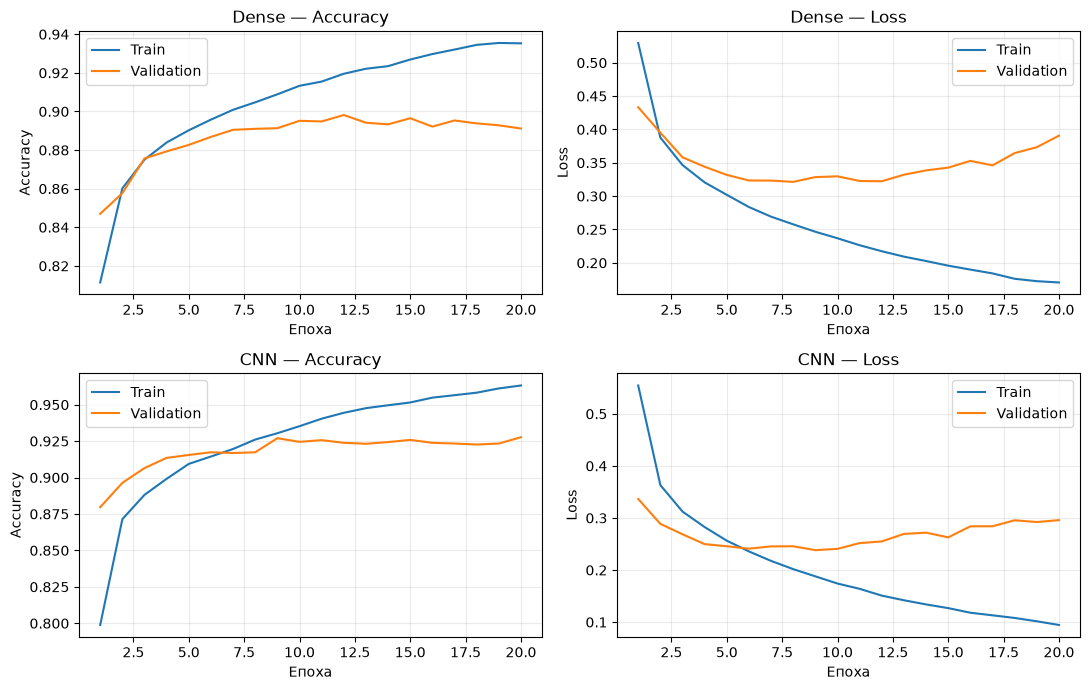

In [5]:
fig, axes = plt.subplots(len(histories), 2, figsize=(11, 7), squeeze=False)

for (name, history), (ax_acc, ax_loss) in zip(histories.items(), axes):
    for ax, metric in ((ax_acc, "accuracy"), (ax_loss, "loss")):
        label = metric.capitalize()
        ax.plot(history.index, history[metric], label="Train", color="tab:blue")
        ax.plot(history.index, history[f"val_{metric}"], label="Validation", color="tab:orange")
        ax.set(title=f"{name} — {label}", xlabel="Епоха", ylabel=label)
        ax.grid(alpha=0.25)
        ax.legend()

fig.tight_layout()
plt.show()

In [6]:
results = []

for name, model in models.items():
    metrics = model.evaluate(x_test, y_test, batch_size=BATCH_SIZE, verbose=0, return_dict=True)
    results.append({
        "Модель": name,
        "Параметри": model.count_params(),
        "Test accuracy": metrics["accuracy"],
        "Test loss": metrics["loss"],
    })

results_df = pd.DataFrame(results).set_index("Модель")
display(results_df.assign(**{
    "Test accuracy": results_df["Test accuracy"].map("{:.2%}".format),
    "Test loss": results_df["Test loss"].map("{:.4f}".format),
}))

accuracy_gap = results_df.loc["CNN", "Test accuracy"] - results_df.loc["Dense", "Test accuracy"]
print(f"Різниця точності CNN мінус Dense — {accuracy_gap * 100:+.2f} в. п.")

,Параметри,Test accuracy,Test loss
Модель,,,
Dense,109386,89.09%,0.3814
CNN,220234,92.45%,0.2837


Різниця точності CNN мінус Dense — +3.36 в. п.


Готуємо шість фото у форматі 28×28 та показуємо очікуваний клас і прогнози обох моделей.

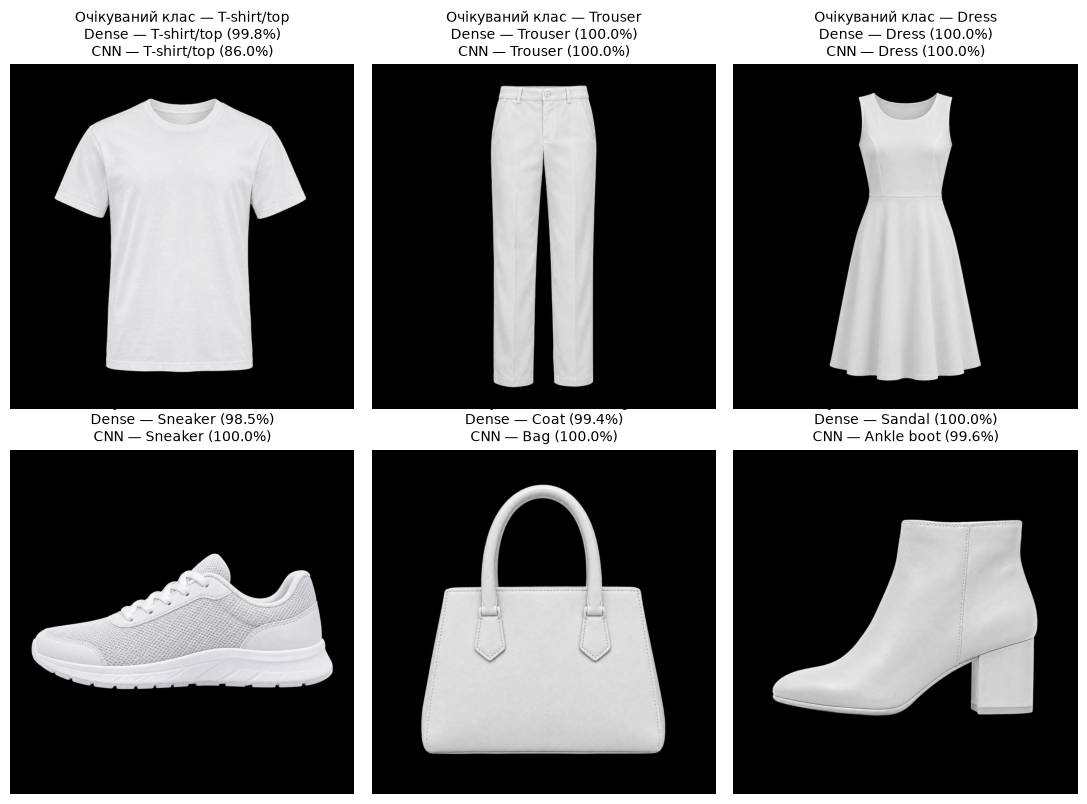

In [7]:
examples = {
    "tshirt.png": 0,
    "trouser.png": 1,
    "dress.png": 3,
    "sneaker.png": 7,
    "bag.png": 8,
    "ankle_boot.png": 9,
}


def prepare_photo(path):
    with Image.open(path) as photo:
        photo = ImageOps.exif_transpose(photo).convert("L")
        image = ImageOps.pad(photo, (28, 28), method=Image.Resampling.LANCZOS, color=0)
    return np.asarray(image, dtype=np.float32)[..., None] / np.float32(255)


photo_batch = np.stack([prepare_photo(TEST_IMAGES / filename) for filename in examples])
predictions = {
    name: tf.nn.softmax(model.predict(photo_batch, verbose=0), axis=1).numpy()
    for name, model in models.items()
}

fig, axes = plt.subplots(2, 3, figsize=(11, 8))
for index, (ax, (filename, expected)) in enumerate(zip(axes.flat, examples.items())):
    with Image.open(TEST_IMAGES / filename) as photo:
        ax.imshow(photo)
    lines = [f"Очікуваний клас — {LABELS[expected]}"]
    for name, probabilities in predictions.items():
        predicted = probabilities[index].argmax()
        lines.append(f"{name} — {LABELS[predicted]} ({probabilities[index, predicted]:.1%})")
    ax.set_title("\n".join(lines), fontsize=10)
    ax.axis("off")

fig.tight_layout()
plt.show()